<h1><center> Breast Cancer Detection using XGBoost

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

In [4]:
X, y = load_breast_cancer(return_X_y= True)

In [5]:
X

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]])

In [6]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

455 455
114 114


#### First experiment : Decison Tree Classifier

-- Decison Tree --
Accuracy =  0.9298245614035088
Classification report : 
               precision    recall  f1-score   support

           0       0.91      0.91      0.91        43
           1       0.94      0.94      0.94        71

    accuracy                           0.93       114
   macro avg       0.93      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114



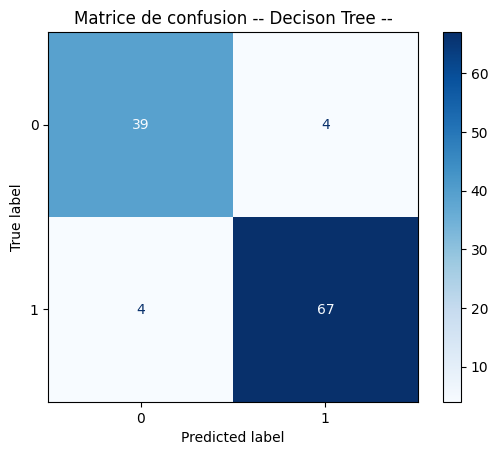

In [10]:
model_DT = DecisionTreeClassifier()
model_DT.fit(X_train, y_train)

y_pred_DT = model_DT.predict(X_test)

acc_DT = accuracy_score(y_test, y_pred_DT)
report_DT = classification_report(y_test, y_pred_DT)
conf_mat_DT = confusion_matrix(y_test, y_pred_DT)
disp = ConfusionMatrixDisplay(conf_mat_DT)

print("-- Decison Tree --")
print("Accuracy = ", acc_DT)
print("Classification report : \n", report_DT)

disp.plot(cmap= 'Blues')
plt.title("Matrice de confusion -- Decison Tree --")
plt.show()


#### Second experiment : Random Forest Classifier

-- Random Forest --
Accuracy =  0.956140350877193
Classification report : 
               precision    recall  f1-score   support

           0       0.95      0.93      0.94        43
           1       0.96      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



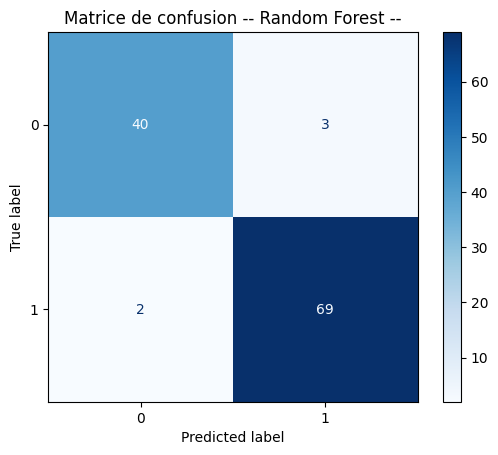

In [15]:
model_RF = RandomForestClassifier()
model_RF.fit(X_train, y_train)

y_pred_RF = model_RF.predict(X_test)

acc_RF = accuracy_score(y_test, y_pred_RF)
report_RF = classification_report(y_test, y_pred_RF)
conf_mat_RF = confusion_matrix(y_test, y_pred_RF)
disp = ConfusionMatrixDisplay(conf_mat_RF)

print("-- Random Forest --")
print("Accuracy = ", acc_RF)
print("Classification report : \n", report_RF)

disp.plot(cmap= 'Blues')
plt.title("Matrice de confusion -- Random Forest --")
plt.show()


#### Third experiment : XGBoost Classifier

-- XGBoost --
Accuracy =  0.9649122807017544
Classification report : 
               precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



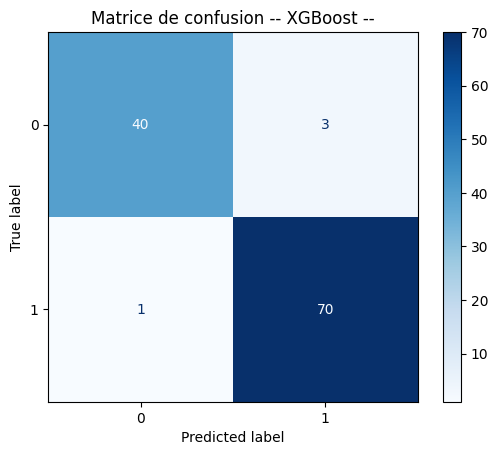

In [14]:
model_XGB = XGBClassifier(
                            n_estimators=100,      # nombre d'arbres
                            learning_rate=0.1,     # taux d'apprentissage
                            max_depth=3,           # profondeur des arbres
                            subsample=0.8,         # fraction d'échantillons par arbre
                            colsample_bytree=0.8,  # fraction de features par arbre
                            random_state=42
)
model_XGB.fit(X_train, y_train)

y_pred_XGB = model_XGB.predict(X_test)

acc_XGB = accuracy_score(y_test, y_pred_XGB)
report_XGB = classification_report(y_test, y_pred_XGB)
conf_mat_XGB = confusion_matrix(y_test, y_pred_XGB)
disp = ConfusionMatrixDisplay(conf_mat_XGB)

print("-- XGBoost --")
print("Accuracy = ", acc_XGB)
print("Classification report : \n", report_XGB)

disp.plot(cmap= 'Blues')
plt.title("Matrice de confusion -- XGBoost --")
plt.show()


<h1><center> FIN